# Notebook 12: Rolling-Window Walk-Forward Portfolio Backtesting

**Project:** Factor Investing and Portfolio Optimization in Indian Markets  
**Universe:** Reliance, TCS, Infosys, HDFC Bank, ICICI Bank  
**Data period:** 2020–2025

## Objective

A single train/test split can make portfolio performance depend heavily on one chosen date. This notebook uses a **walk-forward evaluation**: estimate portfolio weights using only past data, hold those weights for a future period, then re-estimate using the information available at the next rebalance.

We compare:
- Equal-weight baseline
- Rolling-window global minimum-variance portfolio
- Rolling-window maximum-Sharpe portfolio

### Implementation assumptions

- Adjusted daily prices are downloaded using `yfinance` with `auto_adjust=True`.
- At each rebalance date, estimates use only returns observed before that date.
- Weights are held constant between rebalances, with daily portfolio returns computed as the weighted sum of asset returns.
- A one-day execution delay is applied after each signal/rebalance date to reduce look-ahead risk.
- Transaction costs are modeled as turnover multiplied by a user-defined one-way cost rate.
- The universe is deliberately small; this is an educational research experiment, not investment advice.

## 1. Setup and parameters

In [1]:
# In Colab, uncomment if a package is missing:
# %pip install -q yfinance scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from IPython.display import display

SEED = 42
TRADING_DAYS = 252
START_DATE = "2020-01-01"
END_DATE = "2026-01-01"  # exclusive

TRAINING_WINDOW = 756       # approximately 3 trading years
REBALANCE_EVERY = 63        # approximately quarterly
MIN_TRAINING_OBS = 504      # require at least 2 years
RISK_FREE_RATE = 0.06
TRANSACTION_COST_BPS = 10   # one-way cost in basis points

TICKERS = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]
ASSET_NAMES = {
    "RELIANCE.NS": "Reliance",
    "TCS.NS": "TCS",
    "INFY.NS": "Infosys",
    "HDFCBANK.NS": "HDFC Bank",
    "ICICIBANK.NS": "ICICI Bank",
}
np.random.seed(SEED)
print("Parameters loaded.")

Parameters loaded.


## 2. Download and prepare adjusted prices

In [2]:
raw = yf.download(
    TICKERS, start=START_DATE, end=END_DATE,
    auto_adjust=True, progress=False, group_by="column", threads=True
)
if raw.empty:
    raise RuntimeError("No price data returned. Check internet access and ticker symbols.")

if isinstance(raw.columns, pd.MultiIndex):
    if "Close" in raw.columns.get_level_values(0):
        prices = raw["Close"].copy()
    elif "Close" in raw.columns.get_level_values(1):
        prices = raw.xs("Close", axis=1, level=1).copy()
    else:
        raise KeyError("Could not locate Close prices in the downloaded data.")
else:
    raise ValueError("Expected a multi-ticker price table but received a single-level table.")

missing = [ticker for ticker in TICKERS if ticker not in prices.columns]
if missing:
    raise ValueError(f"Missing tickers in downloaded data: {missing}")

prices = prices[TICKERS].sort_index().dropna(how="any")
prices = prices.loc[~prices.index.duplicated(keep="first")]
returns = prices.pct_change().replace([np.inf, -np.inf], np.nan).dropna()
returns = returns.rename(columns=ASSET_NAMES)

if len(returns) <= TRAINING_WINDOW + MIN_TRAINING_OBS:
    raise ValueError("Not enough observations for the selected rolling training window.")

print(f"Observations: {len(returns):,}")
print(f"Date range: {returns.index.min().date()} to {returns.index.max().date()}")
display(prices.head())

Observations: 1,486
Date range: 2020-01-02 to 2025-12-31


Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,672.216187,1821.427124,619.740173,595.677185,514.797913
2020-01-02,683.660217,1813.065918,617.932068,599.474121,518.490417
2020-01-03,684.484009,1849.198486,627.436218,590.925171,516.811951
2020-01-06,668.609375,1849.030640,621.422546,578.136658,504.199829
2020-01-07,678.895630,1853.568604,612.212769,587.291260,501.514404


## 3. Portfolio optimization functions

For annualized mean returns $$(\mu)$$ and covariance matrix $$(\Sigma),$$ we impose long-only weights and a fully invested portfolio:

$$[
w_i\geq 0,\qquad \sum_i w_i=1.
]$$

The minimum-variance portfolio minimizes $$(w^\top\Sigma w)$$. The maximum-Sharpe portfolio maximizes $$((w^\top\mu-r_f)/\sqrt{w^\top\Sigma w}).$$ The maximum-Sharpe objective is particularly sensitive to noisy expected-return estimates.

In [3]:
ASSETS = list(returns.columns)
N_ASSETS = len(ASSETS)
BOUNDS = tuple((0.0, 1.0) for _ in range(N_ASSETS))
CONSTRAINTS = ({"type": "eq", "fun": lambda w: np.sum(w) - 1.0},)
EQUAL_WEIGHTS = np.repeat(1 / N_ASSETS, N_ASSETS)

def portfolio_volatility(weights, covariance):
    variance = float(weights @ covariance.values @ weights)
    return float(np.sqrt(max(variance, 0.0)))

def portfolio_sharpe(weights, mean_returns, covariance, risk_free_rate=RISK_FREE_RATE):
    vol = portfolio_volatility(weights, covariance)
    if vol <= 1e-12:
        return np.nan
    return (float(weights @ mean_returns.values) - risk_free_rate) / vol

def optimize_weights(mean_returns, covariance, method):
    if method == "min_variance":
        objective = lambda w: float(w @ covariance.values @ w)
    elif method == "max_sharpe":
        objective = lambda w: -portfolio_sharpe(w, mean_returns, covariance)
    else:
        raise ValueError("Unknown optimization method.")

    result = minimize(
        objective, x0=EQUAL_WEIGHTS.copy(), method="SLSQP",
        bounds=BOUNDS, constraints=CONSTRAINTS,
        options={"maxiter": 1500, "ftol": 1e-10},
    )
    if not result.success:
        # Fall back to equal weights rather than stopping the entire walk-forward run.
        return pd.Series(EQUAL_WEIGHTS, index=ASSETS), False
    weights = np.clip(result.x, 0.0, 1.0)
    weights = weights / weights.sum()
    return pd.Series(weights, index=ASSETS), True

## 4. Build rebalance dates

The first portfolio weights are estimated only after the required historical training window is available. Rebalance dates are spaced approximately one quarter apart. The resulting weight is applied from the next available trading day.

In [4]:
first_signal_position = max(TRAINING_WINDOW, MIN_TRAINING_OBS)
signal_positions = list(range(first_signal_position, len(returns), REBALANCE_EVERY))

if not signal_positions:
    raise ValueError("No rebalance dates were generated. Reduce the training window or check data coverage.")

rebalance_schedule = pd.DataFrame({
    "Signal Date": [returns.index[pos] for pos in signal_positions],
    "Execution Date": [returns.index[pos + 1] if pos + 1 < len(returns) else pd.NaT
                       for pos in signal_positions],
    "Training Start": [returns.index[max(0, pos - TRAINING_WINDOW)] for pos in signal_positions],
})
rebalance_schedule = rebalance_schedule.dropna(subset=["Execution Date"]).reset_index(drop=True)
display(rebalance_schedule.head())
print(f"Scheduled rebalances: {len(rebalance_schedule)}")

,Signal Date,Execution Date,Training Start
0,2023-01-16,2023-01-17,2020-01-02
1,2023-04-21,2023-04-24,2020-04-03
2,2023-07-21,2023-07-24,2020-07-08
3,2023-10-23,2023-10-25,2020-10-06
4,2024-01-25,2024-01-29,2021-01-05


Scheduled rebalances: 12


## 5. Estimate weights at each rebalance

Each estimate uses a trailing window ending at the signal date. No returns after the signal date are used to estimate that rebalance's weights.

In [5]:
weight_records = []
optimization_log = []

for row in rebalance_schedule.itertuples(index=False):
    signal_date = row[0]
    execution_date = row[1]
    signal_pos = returns.index.get_loc(signal_date)

    window_start = max(0, signal_pos - TRAINING_WINDOW)
    train_window = returns.iloc[window_start:signal_pos].copy()

    if len(train_window) < MIN_TRAINING_OBS:
        continue

    mu = train_window.mean() * TRADING_DAYS
    covariance = train_window.cov() * TRADING_DAYS

    w_min, ok_min = optimize_weights(mu, covariance, "min_variance")
    w_sharpe, ok_sharpe = optimize_weights(mu, covariance, "max_sharpe")

    for strategy, weights, success in [
        ("Equal Weight", pd.Series(EQUAL_WEIGHTS, index=ASSETS), True),
        ("Rolling Minimum Variance", w_min, ok_min),
        ("Rolling Maximum Sharpe", w_sharpe, ok_sharpe),
    ]:
        record = {
            "Signal Date": signal_date,
            "Execution Date": execution_date,
            "Strategy": strategy,
            "Optimization Success": success,
        }
        record.update(weights.to_dict())
        weight_records.append(record)

    optimization_log.append({
        "Signal Date": signal_date,
        "Execution Date": execution_date,
        "Minimum Variance Success": ok_min,
        "Maximum Sharpe Success": ok_sharpe,
        "Training Observations": len(train_window),
    })

weights_long = pd.DataFrame(weight_records)
optimization_log = pd.DataFrame(optimization_log)

if weights_long.empty:
    raise RuntimeError("No weights were generated. Check the rolling window and date schedule.")

display(optimization_log.head())
print(f"Successful/minimally handled optimization dates: {len(optimization_log)}")

,Signal Date,Execution Date,Minimum Variance Success,Maximum Sharpe Success,Training Observations
0,2023-01-16,2023-01-17,True,True,756
1,2023-04-21,2023-04-24,True,True,756
2,2023-07-21,2023-07-24,True,True,756
3,2023-10-23,2023-10-25,True,True,756
4,2024-01-25,2024-01-29,True,True,756


Successful/minimally handled optimization dates: 12


## 6. Convert target weights into daily portfolio returns

Weights are effective from their execution date until the next scheduled execution date. Turnover is calculated as half the sum of absolute weight changes, a common measure of one-way portfolio turnover. The initial portfolio is treated as starting from cash, so its initial turnover is 100%.

In [6]:
cost_rate = TRANSACTION_COST_BPS / 10000.0
strategies = ["Equal Weight", "Rolling Minimum Variance", "Rolling Maximum Sharpe"]
daily_results = {}
daily_turnover = {}

for strategy in strategies:
    strategy_weights = weights_long[weights_long["Strategy"] == strategy].copy()
    strategy_weights = strategy_weights.sort_values("Execution Date")
    targets = strategy_weights.set_index("Execution Date")[ASSETS]

    # Carry each target forward from its execution date. Before the first execution,
    # weights remain missing so those dates are excluded from performance calculations.
    first_exec = strategy_weights["Execution Date"].min()
    target_daily = targets.reindex(returns.index).ffill()
    target_daily = target_daily.loc[first_exec:].reindex(returns.index).ffill()

    aligned_returns = returns.loc[target_daily.index, ASSETS]
    # min_count prevents an all-NaN row (before the first target) becoming a false 0% return.
    gross = (target_daily * aligned_returns).sum(axis=1, min_count=len(ASSETS))

    # Turnover occurs only on execution dates.
    turnover = pd.Series(0.0, index=target_daily.index)
    previous_weights = None
    for date in target_daily.index:
        if date in targets.index:
            current = targets.loc[date].astype(float)
            turnover.loc[date] = 1.0 if previous_weights is None else 0.5 * np.abs(current - previous_weights).sum()
            previous_weights = current.values

    costs = turnover * cost_rate
    net = gross - costs
    daily_results[strategy] = pd.DataFrame({
        "Gross Return": gross,
        "Turnover": turnover,
        "Transaction Cost": costs,
        "Net Return": net,
    })
    daily_turnover[strategy] = turnover

results = {
    strategy: frame for strategy, frame in daily_results.items()
}
print("Daily returns and turnover calculated.")
display(daily_results["Rolling Minimum Variance"].head())

Daily returns and turnover calculated.


,Gross Return,Turnover,Transaction Cost,Net Return
Date,,,,
2020-01-02,NaN,0.0,0.0,NaN
2020-01-03,NaN,0.0,0.0,NaN
2020-01-06,NaN,0.0,0.0,NaN
2020-01-07,NaN,0.0,0.0,NaN
2020-01-08,NaN,0.0,0.0,NaN


## 7. Compare net out-of-sample performance

We evaluate each strategy over the same date range beginning with the first execution date. Metrics include cumulative return, annualized return, annualized volatility, Sharpe ratio, maximum drawdown, and total turnover.

In [7]:
common_start = max(frame.index.min() for frame in daily_results.values())
common_end = min(frame.index.max() for frame in daily_results.values())
common_index = returns.loc[common_start:common_end].index

def performance_metrics(series):
    r = pd.Series(series).reindex(common_index).dropna()
    if r.empty:
        return {
            "Observations": 0, "Cumulative Return": np.nan,
            "Annualized Return": np.nan, "Annualized Volatility": np.nan,
            "Sharpe Ratio": np.nan, "Maximum Drawdown": np.nan,
        }
    growth = (1 + r).cumprod()
    years = len(r) / TRADING_DAYS
    cumulative = growth.iloc[-1] - 1
    annualized_return = growth.iloc[-1] ** (1 / years) - 1 if growth.iloc[-1] > 0 else np.nan
    volatility = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ((r.mean() * TRADING_DAYS) - RISK_FREE_RATE) / volatility if volatility > 0 else np.nan
    drawdown = growth / growth.cummax() - 1
    return {
        "Observations": len(r), "Cumulative Return": cumulative,
        "Annualized Return": annualized_return, "Annualized Volatility": volatility,
        "Sharpe Ratio": sharpe, "Maximum Drawdown": drawdown.min(),
    }

metrics_table = pd.DataFrame({
    strategy: performance_metrics(daily_results[strategy]["Net Return"])
    for strategy in strategies
}).T
metrics_table["Total Turnover"] = {
    strategy: daily_results[strategy]["Turnover"].reindex(common_index).sum()
    for strategy in strategies
}
display(metrics_table.style.format({
    "Cumulative Return": "{:.2%}", "Annualized Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}", "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}", "Total Turnover": "{:.2f}",
    "Observations": "{:.0f}",
}))

,Observations,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Total Turnover
Equal Weight,729,32.10%,10.10%,13.48%,0.336,-15.22%,1.00
Rolling Minimum Variance,729,29.30%,9.29%,13.28%,0.283,-13.29%,1.53
Rolling Maximum Sharpe,729,27.63%,8.80%,16.81%,0.229,-18.56%,3.16


## 8. Growth and drawdown charts

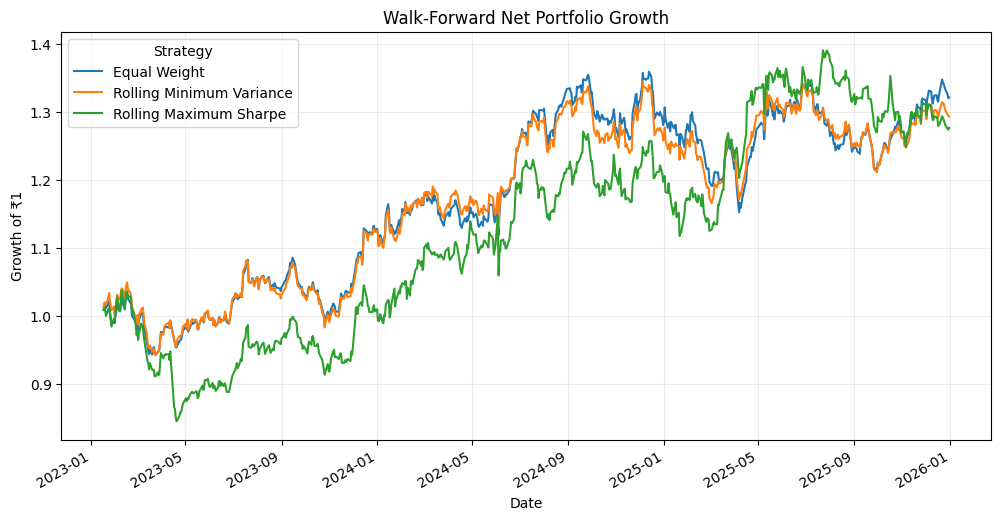

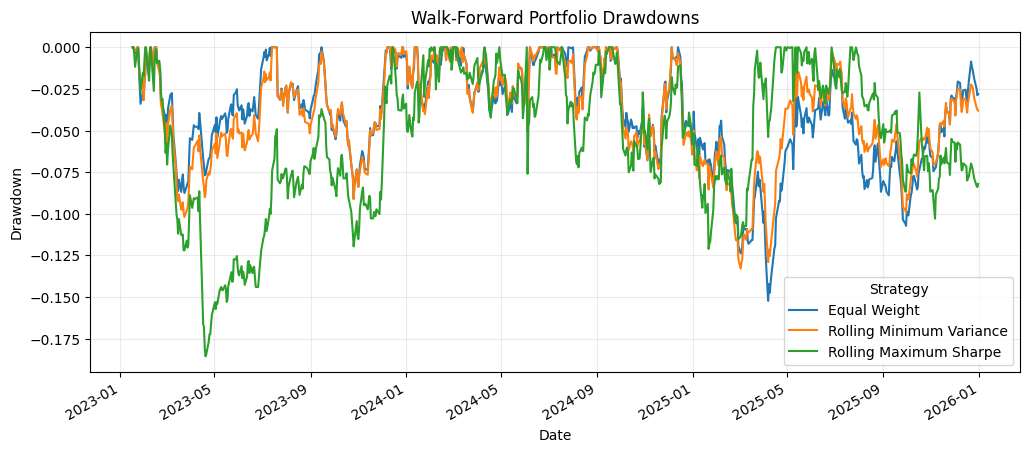

In [8]:
net_returns = pd.DataFrame({
    strategy: daily_results[strategy]["Net Return"].reindex(common_index)
    for strategy in strategies
})
growth = (1 + net_returns).cumprod()
fig, ax = plt.subplots(figsize=(12, 6))
growth.plot(ax=ax)
ax.set_title("Walk-Forward Net Portfolio Growth")
ax.set_ylabel("Growth of ₹1")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend(title="Strategy")
plt.show()

drawdowns = growth.div(growth.cummax()).sub(1)
fig, ax = plt.subplots(figsize=(12, 5))
drawdowns.plot(ax=ax)
ax.set_title("Walk-Forward Portfolio Drawdowns")
ax.set_ylabel("Drawdown")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend(title="Strategy")
plt.show()

## 9. Weight stability through time

Large weight changes may indicate unstable inputs. The chart below shows the rolling maximum-Sharpe allocations at each execution date.

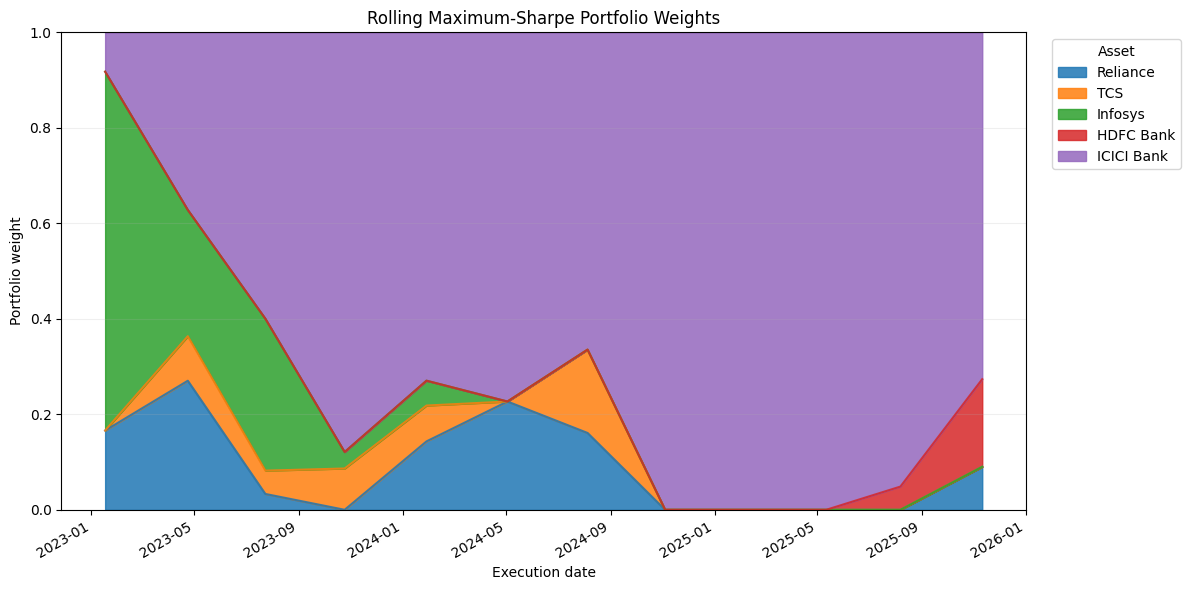

In [9]:
max_sharpe_weights = weights_long[weights_long["Strategy"] == "Rolling Maximum Sharpe"].copy()
max_sharpe_weights = max_sharpe_weights.set_index("Execution Date")[ASSETS]
ax = max_sharpe_weights.plot(kind="area", stacked=True, figsize=(12, 6), alpha=0.85)
ax.set_title("Rolling Maximum-Sharpe Portfolio Weights")
ax.set_ylabel("Portfolio weight")
ax.set_xlabel("Execution date")
ax.set_ylim(0, 1)
ax.legend(title="Asset", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Transaction-cost sensitivity

The backtest stores gross returns and turnover separately. Recompute net performance under different one-way cost assumptions without rerunning the optimizer.

,Equal Weight,Rolling Minimum Variance,Rolling Maximum Sharpe
0 bps,32.23%,29.50%,28.03%
5 bps,32.16%,29.40%,27.83%
10 bps,32.10%,29.30%,27.63%
20 bps,31.97%,29.11%,27.23%
30 bps,31.83%,28.91%,26.83%


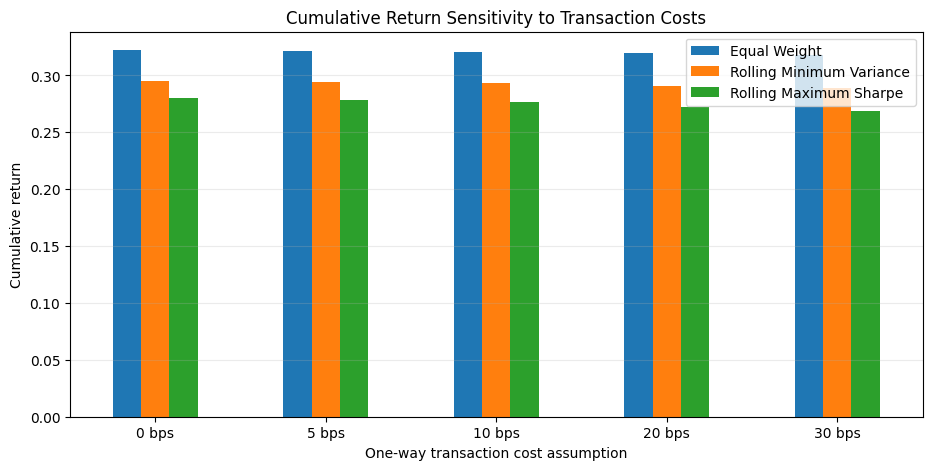

In [10]:
cost_sensitivity = {}
for bps in [0, 5, 10, 20, 30]:
    row_metrics = {}
    rate = bps / 10000.0
    for strategy in strategies:
        frame = daily_results[strategy].reindex(common_index)
        net = frame["Gross Return"] - frame["Turnover"] * rate
        m = performance_metrics(net)
        row_metrics[strategy] = m["Cumulative Return"]
    cost_sensitivity[f"{bps} bps"] = row_metrics

cost_sensitivity_table = pd.DataFrame(cost_sensitivity).T
display(cost_sensitivity_table.style.format("{:.2%}"))

ax = cost_sensitivity_table.plot(kind="bar", figsize=(11, 5))
ax.set_title("Cumulative Return Sensitivity to Transaction Costs")
ax.set_ylabel("Cumulative return")
ax.set_xlabel("One-way transaction cost assumption")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.show()

## 11. Optimization diagnostics

Review how often optimizers failed and fell back to equal weights. Frequent failures would mean the optimization settings or numerical inputs need attention.

In [11]:
diagnostics = pd.DataFrame({
    "Minimum Variance Success Rate": [optimization_log["Minimum Variance Success"].mean()],
    "Maximum Sharpe Success Rate": [optimization_log["Maximum Sharpe Success"].mean()],
    "Number of Rebalances": [len(optimization_log)],
})
display(diagnostics.style.format({
    "Minimum Variance Success Rate": "{:.1%}",
    "Maximum Sharpe Success Rate": "{:.1%}",
    "Number of Rebalances": "{:.0f}",
}))

,Minimum Variance Success Rate,Maximum Sharpe Success Rate,Number of Rebalances
0,100.0%,100.0%,12


## 12. Interpretation and limitations

Use the tables and charts to answer:

1. Did rolling minimum variance reduce volatility or drawdown relative to equal weight?
2. Did rolling maximum Sharpe outperform after transaction costs?
3. How much did turnover reduce cumulative performance at higher cost assumptions?
4. Are maximum-Sharpe weights stable, or do they concentrate in different stocks over time?
5. How often did the optimizers fail and fall back to equal weights?

### Limitations
- The universe contains only five stocks.
- Historical mean and covariance estimates can be noisy.
- Quarterly rebalancing and a three-year window are design choices, not universal optima.
- The daily portfolio-return calculation approximates constant-weight rebalancing between scheduled dates.
- Transaction costs are simplified as turnover multiplied by a fixed basis-point rate; taxes, slippage, liquidity, and market impact are omitted.
- The first evaluation date is delayed until sufficient history is available.

### Conclusion
This notebook replaces a single train/test split with a sequence of historical training windows and forward evaluation periods. The main goal is to test whether optimization results persist across time, after accounting for a simplified turnover-based transaction-cost model. Treat all findings as exploratory rather than predictive.